# Entrenamiento (ResNet-50, DenseNet-121 y ViT-B/16)

**CNNs vs Transformers para clasificación de melanoma (ISIC 2020)**

| | ResNet-50 | DenseNet-121 | ViT-B/16 |
|---|---|---|---|
| Familia | CNN | CNN | Vision Transformer |
| Idea clave | Conexiones residuales | Conexiones densas (concatenación) | Self-attention global entre parches de 16×16 |



In [ ]:
## Standard libraries
import os
import json
import time
import shutil
import random
import numpy as np
import pandas as pd

## Imports for plotting
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf') # For export
import seaborn as sns
sns.set()

## PyTorch
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim
## Torchvision
import torchvision
from torchvision import transforms, models

## PyTorch Lightning
import pytorch_lightning as pl
from pytorch_lightning.callbacks import LearningRateMonitor, ModelCheckpoint, EarlyStopping, Callback
# Tensorboard extension (for visualization purposes later)
%load_ext tensorboard

## Utils del proyecto (dataset y métricas)
from isic_utils import ISICDataset, compute_metrics, best_f1_threshold

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [ ]:
# Path to the folder with the 256 px images and the split from 01_EDA_y_split.ipynb
DATASET_PATH = r"C:\datasets\isic2020"
# Path to the folder where the trained models are saved
CHECKPOINT_PATH = "saved_models"
# Path to the folder where training histories, predictions and summaries are saved
RESULTS_PATH = "results"

# Prueba rápida: True = pocas imágenes y 1 época para verificar que todo corre (~3 min).
# Para el entrenamiento real dejarlo en False.
QUICK_TEST = False
if QUICK_TEST:
    CHECKPOINT_PATH, RESULTS_PATH = "saved_models_test", "results_test"
os.makedirs(CHECKPOINT_PATH, exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)

MAX_EPOCHS = 1 if QUICK_TEST else 15  
PATIENCE = 5                          

# Function for setting the seed
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
set_seed(42)

# Ensure that all operations are deterministic on GPU (if used) for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda:0") if torch.cuda.is_available() else torch.device("cpu")
print("Device:", device)

Device: cuda:0


## Datos

Cargamos la división train/val/test del notebook 01 (70/15/15, agrupada por paciente y estratificada).

In [16]:
df = pd.read_csv(os.path.join(DATASET_PATH, "train_256_split.csv"))

if QUICK_TEST:
    # Submuestra pequeña que conserva positivos en cada conjunto
    df = pd.concat([g[g.target == 1].head(n // 8).pipe(lambda p: pd.concat([p, g[g.target == 0].head(n - len(p))]))
                    for s, n in [("train", 512), ("val", 256), ("test", 256)]
                    for g in [df[df.split == s]]])

train_df, val_df, test_df = [df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"]]

# (nuevo) Peso de la clase positiva para la pérdida: negativos / positivos en entrenamiento
POS_WEIGHT = float((train_df.target == 0).sum() / (train_df.target == 1).sum())

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):6,} imágenes | {d.target.sum():4} melanomas ({d.target.mean():.2%})")
print(f"pos_weight = {POS_WEIGHT:.1f}")

train: 22,889 imágenes |  404 melanomas (1.77%)
val  :  4,910 imágenes |   89 melanomas (1.81%)
test :  4,902 imágenes |   88 melanomas (1.80%)
pos_weight = 55.7


### Transformaciones y *data augmentation*

El conjunto de entrenamiento usa *augmentation* (flips y `RandomResizedCrop`) y validación/prueba.
- Normalizamos con la media/desviación de **ImageNet** porque los pesos preentrenados se aprendieron con esa normalización.
- Añadimos **flip vertical** (una lesión no tiene "arriba") y `ColorJitter` suave para simular diferencias de iluminación entre dermatoscopios.
- Imágenes de 224×224 (la resolución nativa de los pesos de ImageNet) en lugar de 32×32.

In [17]:
IMG_SIZE = 224
# Estadísticas de ImageNet (las que esperan los pesos preentrenados)
DATA_MEANS = [0.485, 0.456, 0.406]
DATA_STD = [0.229, 0.224, 0.225]

test_transform = transforms.Compose([transforms.Resize(IMG_SIZE),
                                     transforms.CenterCrop(IMG_SIZE),
                                     transforms.ToTensor(),
                                     transforms.Normalize(DATA_MEANS, DATA_STD)
                                     ])
# For training, we add some augmentation. Networks are too powerful and would overfit.
train_transform = transforms.Compose([transforms.RandomHorizontalFlip(),
                                      transforms.RandomVerticalFlip(),
                                      transforms.RandomResizedCrop((IMG_SIZE, IMG_SIZE), scale=(0.6, 1.0), ratio=(0.8, 1.25)),
                                      transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
                                      transforms.ToTensor(),
                                      transforms.Normalize(DATA_MEANS, DATA_STD)
                                     ])

train_set = ISICDataset(train_df, transform=train_transform)
val_set = ISICDataset(val_df, transform=test_transform)
test_set = ISICDataset(test_df, transform=test_transform)

# We define a set of data loaders that we can use for various purposes later.
# (nuevo) persistent_workers evita recrear los workers en cada época (en Windows tardan en arrancar)
train_loader = data.DataLoader(train_set, batch_size=16, shuffle=True, drop_last=True, pin_memory=True, num_workers=8, persistent_workers=True)
val_loader = data.DataLoader(val_set, batch_size=64, shuffle=False, drop_last=False, num_workers=8, persistent_workers=True)
test_loader = data.DataLoader(test_set, batch_size=64, shuffle=False, drop_last=False, num_workers=8, persistent_workers=True)

**Batch size:** El entrenamiento usa **batch de 16 con acumulación de gradientes de 2** (`accumulate_grad_batches=2` en el `Trainer`): los gradientes de 2 batches se suman antes de actualizar los pesos, lo que equivale a un **batch efectivo de 32**. Es necesario porque ViT-B/16 (86 M parámetros) no cabe con batch 32 en una GPU de 4 GB(con la cual cuento). Para que el protocolo sea idéntico, los tres modelos usan la misma configuración.

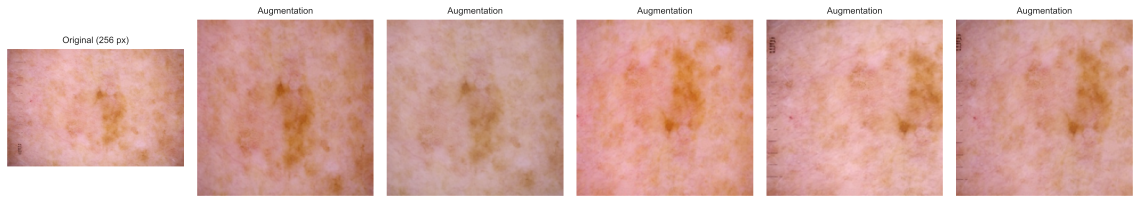

In [18]:
# Visualizamos el efecto de la augmentation sobre una misma imagen
def denormalize(x):
    return (x * torch.tensor(DATA_STD)[:, None, None] + torch.tensor(DATA_MEANS)[:, None, None]).clamp(0, 1)

example = train_df[train_df.target == 1].iloc[[0]]
example_set = ISICDataset(example, transform=train_transform)
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(plt.imread(example.image_path.iloc[0])); axes[0].set_title("Original (256 px)", fontsize=9)
for ax in axes[1:]:
    ax.imshow(denormalize(example_set[0][0]).permute(1, 2, 0)); ax.set_title("Augmentation", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## PyTorch Lightning

Las milestones se escalan a nuestro número de épocas: en clase se reducía el LR en las épocas 100 y 150 de 180 (56 % y 83 %); aquí en las épocas 8 y 12 de 15.

In [19]:
# Setting the seed
pl.seed_everything(42)

Seed set to 42


42

In [ ]:
class ISICModule(pl.LightningModule):

    def __init__(self, model_name, model_hparams, optimizer_name, optimizer_hparams, pos_weight):
        '''
        Inputs:
            model_name - Name of the model to run. Used for creating the model (see function below)
            model_hparams - Hyperparameters for the model, as dictionary.
            optimizer_name - Name of the optimizer to use. Currently supported: Adam, SGD
            optimizer_hparams - Hyperparameters for the optimizer, as dictionary. This includes learning rate, weight decay, etc.
            pos_weight - Weight of the positive class (melanoma) in the loss
        '''
        super().__init__()
        # Exports the hyperparameters to a YAML file, and create "self.hparams" namespace
        self.save_hyperparameters()
        # Create model
        self.model = create_model(model_name, model_hparams)
        # Create loss module  # binaria con peso para la clase positiva
        self.loss_module = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32))
        # Example input for visualizing the graph in Tensorboard
        self.example_input_array = torch.zeros((1, 3, IMG_SIZE, IMG_SIZE), dtype=torch.float32)
        # Probabilidades acumuladas durante la época de validación/prueba
        self.epoch_outputs = []
        self.last_probs = None

    def forward(self, imgs):
        # Forward function that is run when visualizing the graph
        return self.model(imgs).squeeze(1)  # una sola salida: logit de melanoma

    def configure_optimizers(self):
        # We will support Adam or SGD as optimizers.
        if self.hparams.optimizer_name == "Adam":
            # AdamW is Adam with a correct implementation of weight decay (see here for details: https://arxiv.org/pdf/1711.05101.pdf)
            optimizer = optim.AdamW(
                self.parameters(), **self.hparams.optimizer_hparams)
        elif self.hparams.optimizer_name == "SGD":
            optimizer = optim.SGD(self.parameters(), **self.hparams.optimizer_hparams)
        else:
            assert False, f"Unknown optimizer: \"{self.hparams.optimizer_name}\""

        # We will reduce the learning rate by 0.1 after 8 and 12 epochs (en clase: 100 y 150 de 180)
        scheduler = optim.lr_scheduler.MultiStepLR(
            optimizer, milestones=[8, 12], gamma=0.1)
        return [optimizer], [scheduler]

    def training_step(self, batch, batch_idx):
        # "batch" is the output of the training data loader.
        imgs, labels = batch
        preds = self(imgs)
        loss = self.loss_module(preds, labels)
        acc = ((preds > 0).float() == labels).float().mean()

        # Logs the accuracy per epoch to tensorboard (weighted average over batches)
        self.log('train_acc', acc, on_step=False, on_epoch=True)
        self.log('train_loss', loss, on_step=False, on_epoch=True)
        return loss  # Return tensor to call ".backward" on

    def validation_step(self, batch, batch_idx):
        imgs, labels = batch
        preds = self(imgs)
        acc = ((preds > 0).float() == labels).float().mean()
        # By default logs it per epoch (weighted average over batches)
        self.log('val_acc', acc)
        self.log('val_loss', self.loss_module(preds, labels))  # (nuevo)
        self.epoch_outputs.append((torch.sigmoid(preds.float()).cpu(), labels.cpu()))  # (nuevo)

    def test_step(self, batch, batch_idx):
        imgs, labels = batch
        preds = self(imgs)
        acc = ((preds > 0).float() == labels).float().mean()
        # By default logs it per epoch (weighted average over batches), and returns it afterwards
        self.log('test_acc', acc)
        self.epoch_outputs.append((torch.sigmoid(preds.float()).cpu(), labels.cpu()))  # (nuevo)

    # AUC y F1 se calculan con todas las predicciones de la época
    def on_validation_epoch_end(self):
        self._log_epoch_metrics("val")

    def on_test_epoch_end(self):
        self._log_epoch_metrics("test")

    def _log_epoch_metrics(self, prefix):
        probs = torch.cat([p for p, _ in self.epoch_outputs]).numpy()
        labels = torch.cat([l for _, l in self.epoch_outputs]).numpy()
        self.epoch_outputs.clear()
        self.last_probs = probs
        if self.trainer.sanity_checking or labels.min() == labels.max():
            return
        m = compute_metrics(labels, probs, threshold=0.5)
        _, best_f1 = best_f1_threshold(labels, probs)
        self.log_dict({f"{prefix}_auc": m["auc"], f"{prefix}_f1": m["f1"],
                       f"{prefix}_sensitivity": m["sensitivity"], f"{prefix}_best_f1": best_f1})

### Callback para el costo computacional y las curvas de convergencia

Guarda por época: pérdidas, métricas de validación, learning rate, tiempo de la época y memoria máxima de GPU.

In [21]:
class HistoryCallback(Callback):

    def __init__(self):
        self.history = []

    def on_train_start(self, trainer, pl_module):
        torch.cuda.reset_peak_memory_stats()

    def on_train_epoch_start(self, trainer, pl_module):
        self.epoch_start = time.time()
        self.epoch_lr = trainer.optimizers[0].param_groups[0]["lr"]

    def on_train_epoch_end(self, trainer, pl_module):
        # En Lightning la validación ocurre antes de este hook, así que el tiempo incluye train + val
        row = {"epoch": trainer.current_epoch + 1, "lr": self.epoch_lr,
               "epoch_time_s": time.time() - self.epoch_start,
               "peak_gpu_mem_gb": torch.cuda.max_memory_allocated() / 1024**3}
        row.update({k: float(v) for k, v in trainer.callback_metrics.items()})
        self.history.append(row)

## Modelos

Cada modelo se registra en `model_dict` y se crea con `create_model(model_name, model_hparams)`. En lugar de definir las clases nosotros, cargamos las versiones de `torchvision` con pesos de ImageNet y **reemplazamos la última capa** (1000 clases) por una capa lineal con `num_classes` salidas.

In [22]:
model_dict = {}

def create_model(model_name, model_hparams):
    if model_name in model_dict:
        return model_dict[model_name](**model_hparams)
    else:
        assert False, f"Unknown model name \"{model_name}\". Available models are: {str(model_dict.keys())}"

### Función de entrenamiento: guardar resultados

Guardamos el historial por época, el costo computacional y las probabilidades predichas con el proposito de utilizarlo mas adelante en la evaluacion

In [23]:
def save_training_info(save_name, history, train_time, model):
    history = pd.DataFrame(history)
    history.to_csv(os.path.join(RESULTS_PATH, f"history_{save_name}.csv"), index=False)
    info = {"model": save_name,
            "params_M": sum(p.numel() for p in model.parameters()) / 1e6,
            "epochs_trained": len(history),
            "best_epoch": int(history.loc[history.val_auc.idxmax(), "epoch"]),
            "best_val_auc": float(history.val_auc.max()),
            "train_time_min": train_time / 60,
            "mean_epoch_time_min": float(history.epoch_time_s.mean() / 60),
            "peak_gpu_mem_gb": float(history.peak_gpu_mem_gb.max())}
    with open(os.path.join(RESULTS_PATH, f"train_info_{save_name}.json"), "w") as f:
        json.dump(info, f, indent=2)

In [ ]:
def train_model(model_name, save_name=None, **kwargs):
    '''
    Inputs:
        model_name - Name of the model you want to run. Is used to look up the class in "model_dict"
        save_name (optional) - If specified, this name will be used for creating the checkpoint and logging directory.
    '''
    if save_name is None:
        save_name = model_name

    history_cb = HistoryCallback() 
    # Create a PyTorch Lightning trainer with the generation callback
    trainer = pl.Trainer(default_root_dir=os.path.join(CHECKPOINT_PATH, save_name),                          # Where to save models
                         accelerator="gpu" if str(device).startswith("cuda") else "cpu",                     # We run on a GPU (if possible)
                         devices=1,                                                                          # How many GPUs/CPUs we want to use (1 is enough for the notebooks)
                         max_epochs=MAX_EPOCHS,                                                              # How many epochs to train for if no patience is set
                         precision="16-mixed",                                                               # mixed precision to fit in 4 GB of GPU memory
                         accumulate_grad_batches=2,                                                          # 2 batches of 16 = effective batch of 32
                         callbacks=[ModelCheckpoint(save_weights_only=True, mode="max", monitor="val_auc"),  # Save the best checkpoint based on the maximum val_auc recorded. Saves only weights and not optimizer
                                    LearningRateMonitor("epoch"),                                            # Log learning rate every epoch
                                    EarlyStopping(monitor="val_auc", mode="max", patience=PATIENCE),         # stop if val_auc does not improve
                                    history_cb],                                                             # time and memory per epoch
                         enable_progress_bar=True)                                                           # Set to False if you do not want a progress bar
    trainer.logger._log_graph = not model_name.startswith("ViT")  # If True, we plot the computation graph in tensorboard
    trainer.logger._default_hp_metric = None # Optional logging argument that we don't need

    # Check whether pretrained model exists. If yes, load it and skip training
    pretrained_filename = os.path.join(CHECKPOINT_PATH, save_name + ".ckpt")
    if os.path.isfile(pretrained_filename):
        print(f"Found pretrained model at {pretrained_filename}, loading...")
        model = ISICModule.load_from_checkpoint(pretrained_filename) # Automatically loads the model with the saved hyperparameters
    else:
        pl.seed_everything(42) # To be reproducable
        model = ISICModule(model_name=model_name, **kwargs)
        start = time.time()
        trainer.fit(model, train_loader, val_loader)
        save_training_info(save_name, history_cb.history, time.time() - start, model)  # (nuevo)
        # Move the best checkpoint to a fixed name so it is found if the notebook is run again
        shutil.move(trainer.checkpoint_callback.best_model_path, pretrained_filename)
        model = ISICModule.load_from_checkpoint(pretrained_filename) # Load best checkpoint after training

    # Test best model on validation and test set
    val_result = trainer.test(model, val_loader, verbose=False)
    val_probs = model.last_probs
    test_result = trainer.test(model, test_loader, verbose=False)
    test_probs = model.last_probs
    result = {"test": test_result[0], "val": val_result[0]}

    #  Save the predicted probabilities for the later analysis
    preds = pd.concat([val_df.assign(prob=val_probs), test_df.assign(prob=test_probs)])
    preds[["image_name", "split", "target", "prob"]].to_csv(os.path.join(RESULTS_PATH, f"preds_{save_name}.csv"), index=False)

    return model, result

## ResNet-50

Es la versión profunda (50 capas, 4 etapas `[3, 4, 6, 3]`) de la ResNet que implementamos en clase sobre CIFAR-10 (`[3, 3, 3]`). Usa bloques *bottleneck* (1×1 → 3×3 → 1×1) para reducir el costo de las convoluciones 3×3, y las **conexiones residuales** `x + F(x)` permiten que el gradiente fluya sin degradarse aunque la red sea muy profunda.

In [25]:
def ResNet50(num_classes=1, pretrained=True):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

model_dict["ResNet50"] = ResNet50

In [26]:
resnet_model, resnet_results = train_model(model_name="ResNet50",
                                           model_hparams={"num_classes": 1,
                                                          "pretrained": True},
                                           optimizer_name="Adam",
                                           optimizer_hparams={"lr": 1e-4,
                                                              "weight_decay": 1e-4},
                                           pos_weight=POS_WEIGHT)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Seed set to 42
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

  | Name        | Type              | Params | Mode  | FLOPs | In sizes         | Out sizes
-------------------------------------------------------------------------------------------------
0 | model       | ResNet            | 23.5 M | train | 8.2 B | [1, 3, 224, 224] | [1, 1]   
1 | loss_module | BCEWithLogitsLoss | 0      | tr

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=15` reached.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\python314\Lib\site-packages\torch\jit\_trace.py:1000: FutureWarning: `torch.jit.trace` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\python314\Lib\site-packages\torch\jit\_trace.py:1139: FutureWarning: `torch.jit.trace_method` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\python314\Lib\site-packages\torch\jit\_trace.py:1000: FutureWarning: `torch.jit.trace` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\python314\Lib\site-packages\torch\jit\_trace.py:1139: FutureWarning: `torch.jit.trace_method` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]

In [27]:
# Opens tensorboard in notebook. Adjust the path to your CHECKPOINT_PATH!
%tensorboard --logdir saved_models/ResNet50/

## DenseNet-121

Versión grande de la DenseNet vista en clase. En cada bloque denso, cada capa recibe la **concatenación** de las salidas de todas las capas anteriores, lo que fomenta la reutilización de características y la hace muy eficiente en parámetros (8 M, tres veces menos que ResNet-50). A cambio, las concatenaciones consumen más memoria de activaciones.

In [28]:
def DenseNet121(num_classes=1, pretrained=True):
    model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None)
    model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    return model

model_dict["DenseNet121"] = DenseNet121

In [29]:
densenet_model, densenet_results = train_model(model_name="DenseNet121",
                                               model_hparams={"num_classes": 1,
                                                              "pretrained": True},
                                               optimizer_name="Adam",
                                               optimizer_hparams={"lr": 1e-4,
                                                                  "weight_decay": 1e-4},
                                               pos_weight=POS_WEIGHT)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Seed set to 42
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

  | Name        | Type              | Params | Mode  | FLOPs | In sizes         | Out sizes
-------------------------------------------------------------------------------------------------
0 | model       | DenseNet          | 7.0 M  | train | 5.7 B | [1, 3, 224, 224] | [1, 1]   
1 | loss_module | BCEWithLogitsLoss | 0      | tr

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=15` reached.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\python314\Lib\site-packages\torch\jit\_trace.py:1000: FutureWarning: `torch.jit.trace` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\python314\Lib\site-packages\torch\jit\_trace.py:1139: FutureWarning: `torch.jit.trace_method` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\python314\Lib\site-packages\torch\jit\_trace.py:1000: FutureWarning: `torch.jit.trace` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\python314\Lib\site-packages\torch\jit\_trace.py:1139: FutureWarning: `torch.jit.trace_method` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]

In [30]:
# Opens tensorboard in notebook. Adjust the path to your CHECKPOINT_PATH!
%tensorboard --logdir saved_models/DenseNet121/

## Vision Transformer (ViT-B/16)

Funciona así:

1. **Parches como tokens:** la imagen de 224×224 se divide en 14×14 = **196 parches de 16×16 píxeles**. Cada parche se aplana y se proyecta a un vector de 768 dimensiones (*patch embedding*), como las palabras en un Transformer de lenguaje.
2. **Token `[CLS]` y *position embeddings*:** se añade un token extra aprendible (`[CLS]`) cuya salida final se usa para clasificar, y a cada token se le suma un vector de posición (sin él, el modelo no sabría dónde está cada parche).
3. **12 bloques Transformer:** cada bloque aplica *multi-head self-attention* (12 cabezas), donde **cada parche atiende a todos los demás** desde la primera capa, seguido de un MLP. Ambos con **conexiones residuales** y *LayerNorm*, la misma idea de `x + F(x)` que en ResNet.
4. **Clasificación:** la salida del token `[CLS]` pasa por una capa lineal (`heads.head`), que reemplazamos por una de una salida.

**Diferencia clave con las CNNs:** una convolución solo mira una vecindad local y el campo receptivo crece capa a capa; ViT tiene **campo receptivo global desde la primera capa**, pero **no tiene el sesgo inductivo de localidad** de las convoluciones. Por eso necesita muchos más datos (o un buen preentrenamiento) para aprender qué relaciones espaciales importan.

**Learning rate:** Cada arquitectura usaba sus propios hiperparámetros de optimizador (GoogleNet y DenseNet con Adam lr=1e-3, ResNet con SGD lr=0.1), ViT usa un **learning rate menor (2e-5)**.

In [31]:
def ViT_B16(num_classes=1, pretrained=True):
    model = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1 if pretrained else None)
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    return model

model_dict["ViT_B16"] = ViT_B16

In [32]:
vit_model, vit_results = train_model(model_name="ViT_B16",
                                     model_hparams={"num_classes": 1,
                                                    "pretrained": True},
                                     optimizer_name="Adam",
                                     optimizer_hparams={"lr": 2e-5,
                                                        "weight_decay": 1e-4},
                                     pos_weight=POS_WEIGHT)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Seed set to 42
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

  | Name        | Type              | Params | Mode  | FLOPs  | In sizes         | Out sizes
--------------------------------------------------------------------------------------------------
0 | model       | VisionTransformer | 85.8 M | train | 35.1 B | [1, 3, 224, 224] | [1, 1]   
1 | loss_module | BCEWithLogitsLoss | 0      |

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\cassp\AppData\Roaming\Python\Python314\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]

In [33]:
# Opens tensorboard in notebook. Adjust the path to your CHECKPOINT_PATH!
%tensorboard --logdir saved_models/ViT_B16/

## Resultados

Comparamos los modelos en una tabla. Las métricas con umbral 0.5 (accuracy, F1) son preliminares: con un desbalance tan fuerte el umbral óptimo es otro.

In [34]:
%%html
<!-- Some HTML code to increase font size in the following table -->
<style>
th {font-size: 120%;}
td {font-size: 120%;}
</style>

In [35]:
import tabulate
from IPython.display import display, HTML
all_models = [
    ("ResNet50", resnet_results, resnet_model),
    ("DenseNet121", densenet_results, densenet_model),
    ("ViT_B16", vit_results, vit_model)
]
table = [[model_name,
          f"{model_results['val']['test_auc']:.4f}",
          f"{model_results['test']['test_auc']:.4f}",
          f"{100.0*model_results['test']['test_acc']:4.2f}%",
          f"{model_results['test']['test_f1']:.4f}",
          "{:,}".format(sum([np.prod(p.shape) for p in model.parameters()]))]
         for model_name, model_results, model in all_models]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["Model", "Val AUC", "Test AUC", "Test Accuracy (0.5)", "Test F1 (0.5)", "Num Parameters"])))

Model,Val AUC,Test AUC,Test Accuracy (0.5),Test F1 (0.5),Num Parameters
ResNet50,0.9125,0.8897,83.05%,0.1442,"23,510,081"
DenseNet121,0.9168,0.9217,84.43%,0.1643,"6,954,881"
ViT_B16,0.9097,0.9201,83.13%,0.157,"85,799,425"


### Costo computacional y convergencia

- **Épocas hasta convergencia:** época en la que se alcanzó el 95 % de la mejor AUC de validación, y época del mejor checkpoint.
- **Costo:** parámetros, tiempo por época, tiempo total y memoria máxima de GPU.

In [36]:
MODEL_NAMES = ["ResNet50", "DenseNet121", "ViT_B16"]
MODEL_COLORS = {"ResNet50": "#2a78d6", "DenseNet121": "#eb6834", "ViT_B16": "#1baf7a"}

histories = {m: pd.read_csv(os.path.join(RESULTS_PATH, f"history_{m}.csv")) for m in MODEL_NAMES}
infos = {m: json.load(open(os.path.join(RESULTS_PATH, f"train_info_{m}.json"))) for m in MODEL_NAMES}

rows = []
for m in MODEL_NAMES:
    h, info = histories[m], infos[m]
    epoch_95 = int(h.loc[h.val_auc >= 0.95 * h.val_auc.max(), "epoch"].min())
    rows.append({"modelo": m,
                 "parámetros (M)": round(info["params_M"], 1),
                 "épocas entrenadas": info["epochs_trained"],
                 "época 95% mejor AUC": epoch_95,
                 "mejor época": info["best_epoch"],
                 "min / época": round(info["mean_epoch_time_min"], 2),
                 "tiempo total (min)": round(info["train_time_min"], 1),
                 "memoria GPU (GB)": round(info["peak_gpu_mem_gb"], 2),
                 "mejor AUC val": round(info["best_val_auc"], 4),
                 "mejor F1 val": round(h.loc[h.val_auc.idxmax(), "val_best_f1"], 4)})
summary = pd.DataFrame(rows).set_index("modelo")
summary.to_csv(os.path.join(RESULTS_PATH, "training_summary.csv"))
summary

,parámetros (M),épocas entrenadas,época 95% mejor AUC,mejor época,min / época,tiempo total (min),memoria GPU (GB),mejor AUC val,mejor F1 val
modelo,,,,,,,,,
ResNet50,23.5,15,1,14,3.82,59.1,1.10,0.9125,0.2691
DenseNet121,7.0,15,3,14,5.18,78.8,1.16,0.9168,0.2658
ViT_B16,85.8,11,1,6,10.87,120.7,2.58,0.9097,0.2743


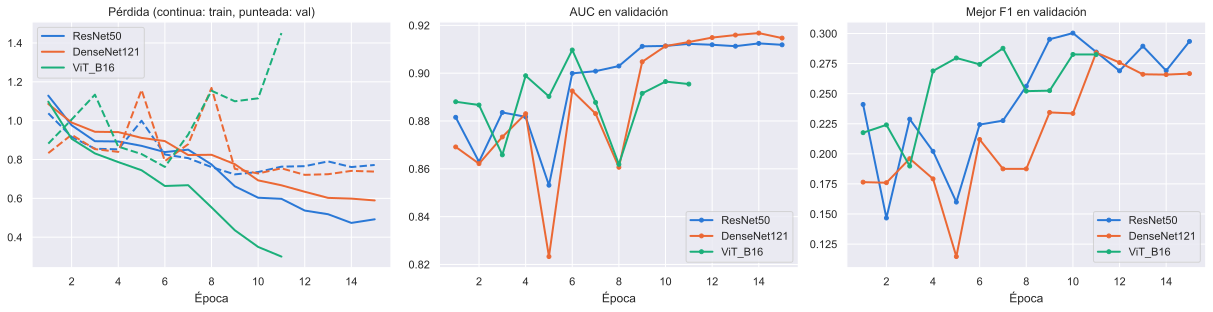

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for m in MODEL_NAMES:
    h, c = histories[m], MODEL_COLORS[m]
    axes[0].plot(h.epoch, h.train_loss, color=c, lw=2, label=m)
    axes[0].plot(h.epoch, h.val_loss, color=c, lw=2, ls="--")
    axes[1].plot(h.epoch, h.val_auc, color=c, lw=2, marker="o", ms=4, label=m)
    axes[2].plot(h.epoch, h.val_best_f1, color=c, lw=2, marker="o", ms=4, label=m)
axes[0].set_title("Pérdida (continua: train, punteada: val)")
axes[1].set_title("AUC en validación")
axes[2].set_title("Mejor F1 en validación")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_PATH, "curvas_entrenamiento.pdf"), bbox_inches="tight")
plt.show()

## Resumen

- Los tres modelos se entrenaron con el mismo protocolo: misma división, resolución, *augmentation*, pérdida, optimizador (AdamW), scheduler, batch efectivo y épocas máximas. La única diferencia es el learning rate de ViT (ver su sección).
- En `saved_models/` queda el mejor checkpoint de cada modelo (según AUC de validación). En `results/`:
  - `history_<modelo>.csv`: métricas por época (curvas de convergencia).
  - `train_info_<modelo>.json` y `training_summary.csv`: costo computacional.
  - `preds_<modelo>.csv`: probabilidades en validación y prueba.

